In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
df_tea = pd.read_csv(r"C:\Users\MCT\Downloads\student_tea_snacks _1_.csv")

In [24]:
print("Shape:", df_tea.shape)

Shape: (100, 7)


In [25]:
print("Columns:", df_tea.columns.tolist())

Columns: ['student_id', 'gender', 'age_group', 'prefers_tea', 'tea_type', 'snack_choice', 'cups_per_day']


In [26]:
print("\nSummary statistics (numeric):")


Summary statistics (numeric):


In [27]:
print(df_tea.describe())

       cups_per_day
count    100.000000
mean       2.810000
std        1.673893
min        0.000000
25%        1.750000
50%        3.000000
75%        4.000000
max        5.000000


In [28]:
print("\nSummary statistics (categorical):")


Summary statistics (categorical):


In [29]:
print(df_tea.describe(include='object'))

       student_id gender age_group prefers_tea tea_type snack_choice
count         100    100       100         100       77          100
unique        100      2         3           2        3            3
top          S001   Male     18-20         Yes    Green       Samosa
freq            1     53        39          51       29           40


C:\Users\MCT\AppData\Local\Temp\ipykernel_21824\2753738609.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df_tea.describe(include='object'))


In [30]:
print("\nQ1 - tea_type value_counts:")
print(df_tea['tea_type'].value_counts(dropna=False))


Q1 - tea_type value_counts:
tea_type
Green          29
Doodh Patti    25
Black          23
NaN            23
Name: count, dtype: int64


In [31]:
print("\nQ2 - cups_per_day by gender:")
print(df_tea.groupby('gender')['cups_per_day'].agg(['count', 'mean', 'median', 'min', 'max', 'std']))


Q2 - cups_per_day by gender:
        count      mean  median  min  max       std
gender                                             
Female     47  2.595745     3.0    0    5  1.752757
Male       53  3.000000     3.0    0    5  1.593255


In [32]:
print("\nQ3 - snack_choice value_counts:")
print(df_tea['snack_choice'].value_counts())


Q3 - snack_choice value_counts:
snack_choice
Samosa     40
Chips      31
Biscuit    29
Name: count, dtype: int64


In [33]:
print("\nQ4 - age_group vs tea_type:")
print(pd.crosstab(df_tea['age_group'], df_tea['tea_type'], margins=True))


Q4 - age_group vs tea_type:


tea_type   Black  Doodh Patti  Green  All
age_group                                
18-20          9           11     13   33
21-23          9            6      5   20
24-26          5            8     11   24
All           23           25     29   77


In [34]:
print("\nQ4b - age_group vs prefers_tea:")
print(pd.crosstab(df_tea['age_group'], df_tea['prefers_tea'], margins=True))


Q4b - age_group vs prefers_tea:
prefers_tea  No  Yes  All
age_group                
18-20        19   20   39
21-23        17   15   32
24-26        13   16   29
All          49   51  100


In [35]:
print("\nQ5 - Don't drink tea checks:")
print("prefers_tea == 'No':", (df_tea['prefers_tea'] == 'No').sum())
print("cups_per_day == 0:", (df_tea['cups_per_day'] == 0).sum())
print("tea_type is NaN:", df_tea['tea_type'].isna().sum())


Q5 - Don't drink tea checks:
prefers_tea == 'No': 49
cups_per_day == 0: 13
tea_type is NaN: 23


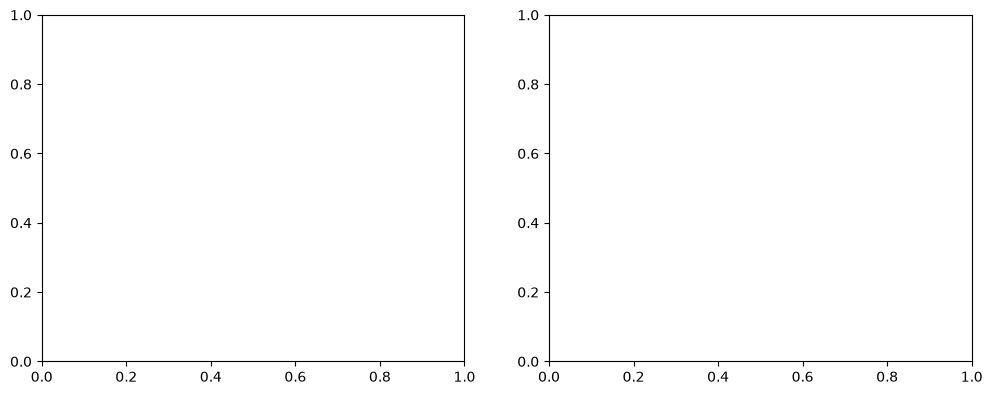

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

In [38]:
snack_counts = df_tea['snack_choice'].value_counts().reset_index()
snack_counts.columns = ['snack_choice', 'count']
sns.barplot(data=snack_counts, x='snack_choice', y='count', ax=axes[0], palette='magma')
axes[0].set_title('Q3: Student Snack Choices')
axes[0].set_xlabel('Snack Choice')
axes[0].set_ylabel('Number of Students')

C:\Users\MCT\AppData\Local\Temp\ipykernel_21824\2966842197.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=snack_counts, x='snack_choice', y='count', ax=axes[0], palette='magma')


Text(4.444444444444466, 0.5, 'Number of Students')

(array([0. , 0.2, 0.4, 0.6, 0.8, 1. ]),
 [Text(0.0, 0, '0.0'),
  Text(0.2, 0, '0.2'),
  Text(0.4, 0, '0.4'),
  Text(0.6000000000000001, 0, '0.6'),
  Text(0.8, 0, '0.8'),
  Text(1.0, 0, '1.0')])

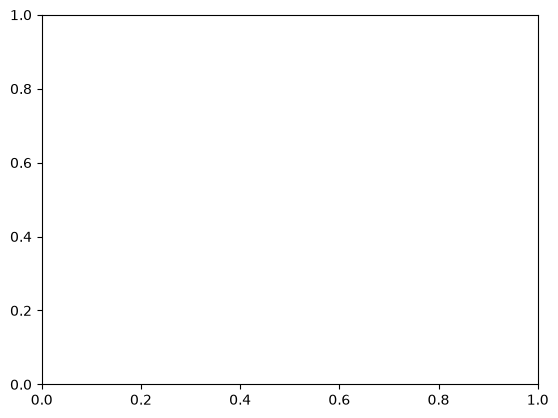

In [39]:
age_tea = pd.crosstab(df_tea['age_group'], df_tea['tea_type'])
age_tea.plot(kind='bar', ax=axes[1], colormap='Set2')
axes[1].set_title('Q4: Tea Preference by Age Group')
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('Number of Students')
axes[1].legend(title='Tea Type')
plt.xticks(rotation=0)

In [40]:
plt.tight_layout()
plt.savefig('student_tea_charts.png', dpi=150)
print("Saved student_tea_charts.png")

Saved student_tea_charts.png


<Figure size 640x480 with 0 Axes>